## Data Exploration and Text Mining

This notebook explores the cleaned dataset built in `Build_Final_Dataset.ipynb` (184,664 moisturizer reviews with skin type and ingredient data).

**1. Data Exploration**
- Basic stats: dataset size, products, brands, date range, and price
- Reviews per year
- Missing values remaining after cleaning
- Review text length, overall and by star rating
- Sample reviews
- Skin type mix, overall and within products

**2. Text Mining Basics**
- Keyword and frequency analysis: top words in low- vs. high-rated reviews and across skin types
- Baseline sentiment analysis: lexicon-based sentiment scores compared against star ratings
- Topic modeling: not used, since it overlaps with Claude's complaint labeling in Phase 3 (explained below)

## Setup

In [1]:
%pip install -q pandas matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
# Imports
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
# Data load
DATA_PATH = "../Data/sephora_moisturizer_reviews_clean.csv.gz"

df = pd.read_csv(DATA_PATH, parse_dates=["submission_time"])
print(f"Loaded {len(df):,} reviews")

Loaded 184,664 reviews


## 1. Data Exploration
### Basic stats

In [4]:
# Helper functions for exploration and plotting

# Dataset Summary
def summarize_dataset(df):
    """Print basic size, coverage, and price stats."""
    print(f"Reviews: {len(df):,}")
    print(f"Products: {df['product_id'].nunique()} | Brands: {df['brand_name'].nunique()}")
    print(f"Date range: {df['submission_time'].min().date()} to {df['submission_time'].max().date()}")
    prices = df.drop_duplicates("product_id")["price_usd"]
    print(f"Product price: median ${prices.median():.0f}, range ${prices.min():.0f}-${prices.max():.0f}")

# Table of counts and percentages
def share_table(df, col):
    """Counts and percentages for one column."""
    counts = df[col].value_counts()
    return pd.DataFrame({"count": counts, "pct": (counts / counts.sum() * 100).round(1)})

# Plotting
def plot_bar(series, title, xlabel, ylabel, rot=0):
    """Simple single-color bar chart. Use rot to angle the x-axis labels."""
    ax = series.plot(kind="bar", color="#4C72B0", figsize=(7, 4), rot=rot)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    if rot:
        plt.setp(ax.get_xticklabels(), ha="right")   # anchor angled labels under their bars
    ax.spines[["top", "right"]].set_visible(False)
    plt.tight_layout()
    plt.show()

In [5]:
summarize_dataset(df)

Reviews: 184,664
Products: 379 | Brands: 90
Date range: 2008-08-29 to 2023-03-21
Product price: median $59, range $8-$400


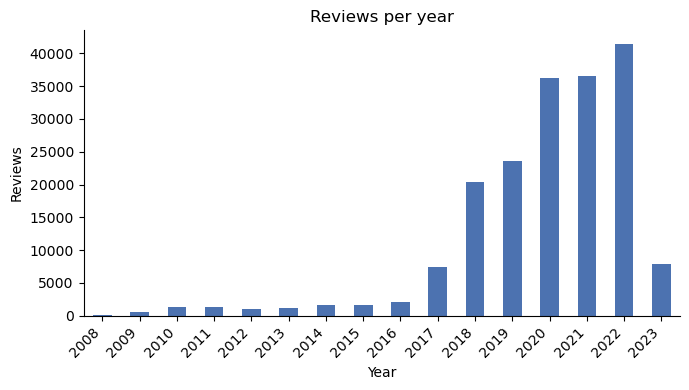

In [6]:
# Plot reviews per year
# Data was scraped in March 2023
plot_bar(df["submission_time"].dt.year.value_counts().sort_index(),
         "Reviews per year", "Year", "Reviews", rot=45)

In [7]:
# Missing values in the cleaned data
print(df.isna().sum())

author_id                0
rating                   0
submission_time          0
review_text              0
review_title         53987
skin_type                0
product_id               0
review_id                0
product_name             0
brand_name               0
price_usd                0
tertiary_category        0
ingredients              0
highlights           25061
dtype: int64


In [8]:
# Calculate the percentage of reviews between 2018 and 2022
years = df["submission_time"].dt.year
print(f"{years.between(2018, 2022).mean():.1%}")

85.7%


**Observations**
- The cleaned dataset has 184,664 reviews of 379 moisturizers from 90 brands. Product prices range from $8 to $400 (median $59), so the data covers drugstore-priced and luxury moisturizers alike.
- Reviews run from August 2008 to March 2023, but most are recent. Volume rose sharply from 2017 onward, and 2018–2022 account for 85.7% of all reviews, while no year before 2017 has more than about 2,100. The low 2023 count (7,929) reflects when the data was scraped (March 2023), not a drop in reviews, since it covers less than three months. For the Phase 3 time check, comparing earlier and later years within 2018–2022 is more reliable than going back further, where yearly counts are too small.
- `Build_Final_Dataset.ipynb` removed about 10,300 reviews that Sephora displays on both the mini and full-size versions of a product, which would otherwise be counted twice, plus reviews missing review text, skin type, ingredients, or subcategory.
- Only two columns still have gaps. Review titles are missing for 53,987 reviews (29.2%), which is acceptable because the analysis relies on review text and uses titles only when present. Highlights (Sephora's product tags) are missing for 25,061 reviews (13.6%); they will only serve as a secondary check on ingredient flags, and a blank means no tags were listed, not that a product lacks a feature.